In [2]:
# Built-in modules
import math

# Imports from Qiskit
from qiskit import QuantumCircuit
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate
from qiskit.visualization import plot_distribution
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Imports from qiskit-ibm-runtime
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler


def grover_oracle(marked_states):
    """Build a Grover oracle for multiple marked states

    Here we assume all input marked states have the same number of bits

    Parameters:
        marked_states (str or list): Marked states of oracle

    Returns:
        QuantumCircuit: Quantum circuit representing Grover oracle
    """
    if not isinstance(marked_states, list):
        marked_states = [marked_states]
    # Compute the number of qubits in circuit
    num_qubits = len(marked_states[0])

    qc = QuantumCircuit(num_qubits)
    # Mark each target state in the input list
    for target in marked_states:
        # Flip target bit-string to match Qiskit bit-ordering
        rev_target = target[::-1]
        # Find the indices of all the '0' elements in bit-string
        zero_inds = [
            ind
            for ind in range(num_qubits)
            if rev_target.startswith("0", ind)
        ]
        # Add a multi-controlled Z-gate with pre- and post-applied X-gates (open-controls)
        # where the target bit-string has a '0' entry
        if zero_inds:
            qc.x(zero_inds)
        qc.compose(MCMTGate(ZGate(), num_qubits - 1, 1), inplace=True)
        if zero_inds:
            qc.x(zero_inds)
    return qc

In [3]:
service = QiskitRuntimeService()

n=3: optimal_iters=2, 2Q depth=37
n=4: optimal_iters=3, 2Q depth=159
n=5: optimal_iters=4, 2Q depth=453
n=6: optimal_iters=6, 2Q depth=1511
n=7: optimal_iters=8, 2Q depth=3312
n=8: optimal_iters=12, 2Q depth=7335
n=9: optimal_iters=17, 2Q depth=12725


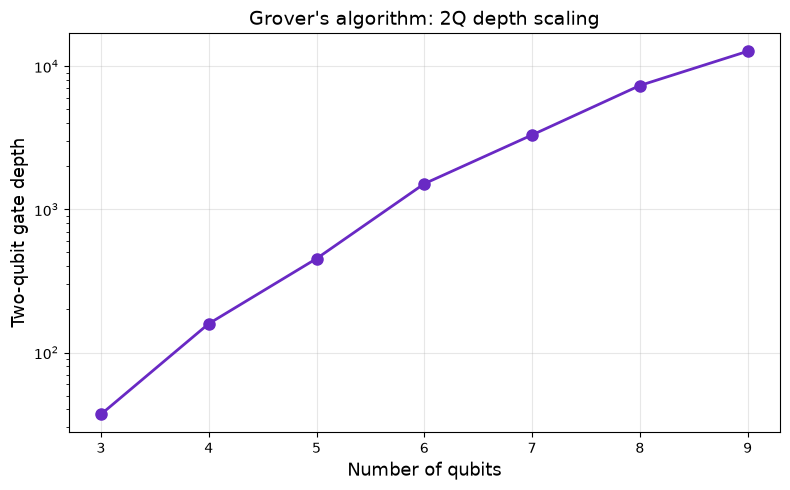

In [4]:
import matplotlib.pyplot as plt

num_qubits_list = list(range(3, 10))
two_q_depths = []
backend = service.least_busy(
    operational=True, simulator=False, min_num_qubits=127
)
for n in num_qubits_list:
    # Mark a single state for simplicity
    marked = ["1" * n]
    oracle_n = grover_oracle(marked)
    grover_op_n = grover_operator(oracle_n)

    # Optimal number of iterations
    num_iters = math.floor(
        math.pi / (4 * math.asin(math.sqrt(len(marked) / 2**n)))
    )

    # Build the full Grover circuit
    qc_n = QuantumCircuit(n)
    qc_n.h(range(n))
    qc_n.compose(grover_op_n.power(num_iters), inplace=True)
    qc_n.measure_all()

    # Transpile to a basis gate set and count 2Q depth
    pm_n = generate_preset_pass_manager(backend=backend, optimization_level=3)
    qc_transpiled = pm_n.run(qc_n)

    # Compute depth restricted to 2-qubit operations
    depth_2q = qc_transpiled.depth(lambda x: x.operation.num_qubits == 2)

    two_q_depths.append(depth_2q)
    print(f"n={n}: optimal_iters={num_iters}, 2Q depth={depth_2q}")

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    num_qubits_list,
    two_q_depths,
    "o-",
    linewidth=2,
    markersize=8,
    color="#6929C4",
)
ax.set_xlabel("Number of qubits", fontsize=13)
ax.set_ylabel("Two-qubit gate depth", fontsize=13)
ax.set_title("Grover's algorithm: 2Q depth scaling", fontsize=14)
ax.set_yscale("log")
ax.grid(True, alpha=0.3)
ax.set_xticks(num_qubits_list)
plt.tight_layout()
plt.show()